In [2]:
import sys 
sys.path.insert(0 ,'../src')

from utils.gpu import setup_gpu

setup_gpu()

I0000 00:00:1792611684.287421  363625 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792611685.496884  363625 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [3]:
import tensorflow as tf 
import numpy as np 
import PIL

In [4]:
base_model = tf.keras.applications.InceptionV3(
    include_top = False,
    weights = 'imagenet',
    pooling = 'avg',
    input_shape = (299,299,3)
)
base_model.trainable = False


In [5]:
img_path = "../data/Train/Glioma/images/gg (103).jpg"
img = PIL.Image.open(img_path).convert("RGB").resize((299,299))
x = np.array(img,dtype='float32')
x = np.expand_dims(x , axis=0)
x = tf.keras.applications.inception_v3.preprocess_input(x)

features = base_model(x , training=False)
print(features.shape)
print(features.device)
print(features.numpy()[0][:10])

(1, 2048)
/job:localhost/replica:0/task:0/device:GPU:0
[0.37456557 0.16951874 0.47338614 0.66522974 0.10052657 0.14199097
 0.36782297 0.3584706  0.05893243 0.12828946]


In [6]:
from pathlib import Path

In [7]:
DATA_DIR = Path("../data")

def print_tree(folder: Path , indent: str) :
    for sub in (subFolder for subFolder in folder.iterdir() if subFolder.is_dir()):
        n_files = sum(1 for file in sub.iterdir() if file.is_file())
        infos = f'--> ({n_files}) files' if n_files else ""
        print(f"{indent}{sub.name}{infos}")
        print_tree(sub , indent + "    ")
        
        
print_tree(DATA_DIR , "     ")

     Train
         Glioma
             images--> (1153) files
             labels--> (1153) files
         Meningioma
             images--> (1449) files
             labels--> (1449) files
         No Tumor
             images--> (711) files
             labels--> (711) files
         Pituitary
             images--> (1424) files
             labels--> (1424) files
     Val
         Glioma
             images--> (136) files
             labels--> (136) files
         Meningioma
             images--> (140) files
             labels--> (140) files
         No Tumor
             images--> (100) files
             labels--> (100) files
         Pituitary
             images--> (136) files
             labels--> (136) files


In [8]:
import pandas as pd

DATA_DIR = Path("../data")
IMG_EXTS = {".jpg", ".jpeg", ".png"}

rows = []
for split_dir in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        images = {f.stem for f in (class_dir / "images").iterdir() if f.suffix.lower() in IMG_EXTS}
        labels = {f.stem for f in (class_dir / "labels").iterdir() if f.suffix == ".txt"}

        rows.append({
            "split": split_dir.name,
            "class": class_dir.name,
            "images": len(images),
            "labels": len(labels),
            "pairs": len(images & labels),             # image AND label
            "images_without_label": len(images - labels),
            "labels_without_image": len(labels - images),
        })

pairing = pd.DataFrame(rows)

trainCount = pairing[pairing['split'] == 'Train']['images']
class_names = pairing['class'].unique()
pairing

,split,class,images,labels,pairs,images_without_label,labels_without_image
0,Train,Glioma,1153,1153,1153,0,0
1,Train,Meningioma,1449,1449,1449,0,0
2,Train,No Tumor,711,711,711,0,0
3,Train,Pituitary,1424,1424,1424,0,0
4,Val,Glioma,136,136,136,0,0
5,Val,Meningioma,140,140,140,0,0
6,Val,No Tumor,100,100,98,2,2
7,Val,Pituitary,136,136,136,0,0


Text(0.5, 1.0, 'Images par classe (Train)')

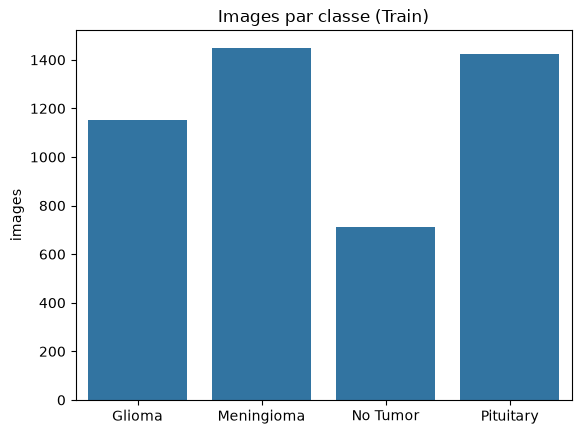

In [9]:
import seaborn as sns

sns.barplot(x=class_names , y=trainCount).set_title("Images par classe (Train)")

In [10]:
train = pairing[pairing["split"] == "Train"]
(train.groupby("class")["images"].sum() / train["images"].sum() * 100).round(1)


class
Glioma        24.3
Meningioma    30.6
No Tumor      15.0
Pituitary     30.1
Name: images, dtype: float64